In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
data = {
    'study_hours': [1, 2, 3, 4, 5, 6, 7, 8, 2, 3,
                    5, 6, 7, 8, 9, 1, 4, 6, 8, 9],

    'attendance': [40, 45, 50, 55, 60, 65, 70, 80, 48, 52,
                   65, 72, 78, 85, 90, 35, 58, 68, 88, 95],

    'previous_score': [30, 35, 40, 45, 50, 55, 60, 75, 38, 42,
                       55, 65, 70, 80, 90, 25, 48, 62, 85, 95],

    'passed': [0, 0, 0, 0, 0, 1, 1, 1, 0, 0,
               1, 1, 1, 1, 1, 0, 0, 1, 1, 1]
}

df = pd.DataFrame(data)

df.head()

,study_hours,attendance,previous_score,passed
0,1,40,30,0
1,2,45,35,0
2,3,50,40,0
3,4,55,45,0
4,5,60,50,0


In [4]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
df.describe()

Dataset shape: (20, 4)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   study_hours     20 non-null     int64
 1   attendance      20 non-null     int64
 2   previous_score  20 non-null     int64
 3   passed          20 non-null     int64
dtypes: int64(4)
memory usage: 772.0 bytes

Statistical summary:


,study_hours,attendance,previous_score,passed
count,20.000000,20.000000,20.000000,20.000000
mean,5.200000,64.950000,57.250000,0.550000
std,2.607681,17.340172,20.300052,0.510418
min,1.000000,35.000000,25.000000,0.000000
25%,3.000000,51.500000,41.500000,0.000000
50%,5.500000,65.000000,55.000000,1.000000
75%,7.250000,78.500000,71.250000,1.000000
max,9.000000,95.000000,95.000000,1.000000


In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
study_hours       0
attendance        0
previous_score    0
passed            0
dtype: int64

Duplicate rows:
0


In [6]:
print("Student results:")
print(df['passed'].value_counts())

print("\nClass distribution:")
print(df['passed'].value_counts().rename(index={
    0: "Failed",
    1: "Passed"
}))

Student results:
passed
1    11
0     9
Name: count, dtype: int64

Class distribution:
passed
Passed    11
Failed     9
Name: count, dtype: int64


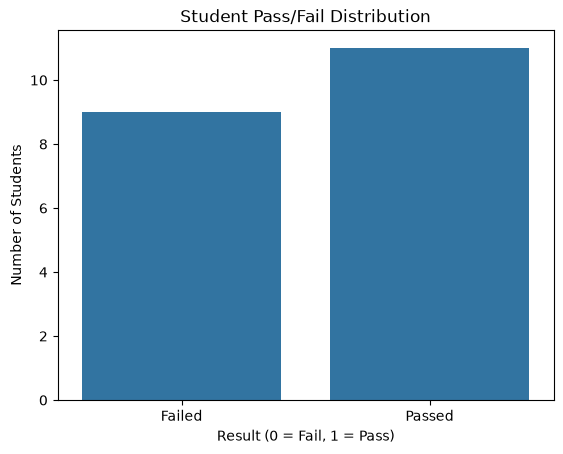

In [7]:
sns.countplot(data=df, x='passed')

plt.title("Student Pass/Fail Distribution")
plt.xlabel("Result (0 = Fail, 1 = Pass)")
plt.ylabel("Number of Students")
plt.xticks([0, 1], ["Failed", "Passed"])

plt.show()

In [8]:
X = df[['study_hours', 'attendance', 'previous_score']]

y = df['passed']

print("Input features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

Input features (X):
   study_hours  attendance  previous_score
0            1          40              30
1            2          45              35
2            3          50              40
3            4          55              45
4            5          60              50

Target (y):
0    0
1    0
2    0
3    0
4    0
Name: passed, dtype: int64


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16, 3)
Testing features: (4, 3)
Training target: (16,)
Testing target: (4,)


In [10]:
model = LogisticRegression()

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [11]:
y_pred = model.predict(X_test)

print("Actual results:")
print(y_test.values)

print("\nPredicted results:")
print(y_pred)

Actual results:
[0 1 1 0]

Predicted results:
[0 1 1 0]


In [12]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 100.0 %


Confusion Matrix:
[[2 0]
 [0 2]]


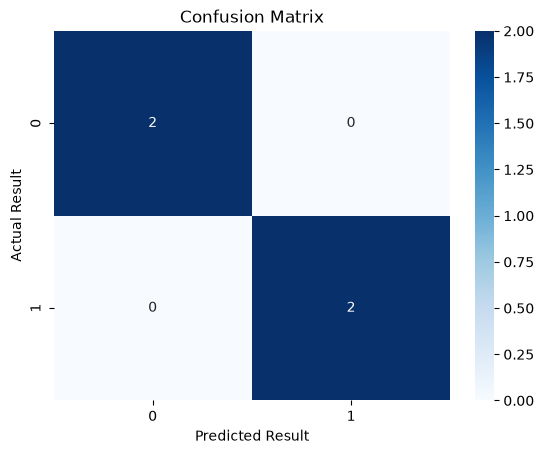

In [13]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Confusion Matrix")

plt.show()

In [14]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Failed", "Passed"],
    zero_division=0
))

              precision    recall  f1-score   support

      Failed       1.00      1.00      1.00         2
      Passed       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



In [15]:
new_student = pd.DataFrame({
    'study_hours': [7],
    'attendance': [80],
    'previous_score': [75]
})

prediction = model.predict(new_student)

print("Prediction:", prediction[0])

if prediction[0] == 1:
    print("Student is predicted to PASS.")
else:
    print("Student is predicted to FAIL.")

Prediction: 1
Student is predicted to PASS.


In [16]:
probabilities = model.predict_proba(new_student)

print("Probability of Fail:", probabilities[0][0] * 100, "%")
print("Probability of Pass:", probabilities[0][1] * 100, "%")

Probability of Fail: 5.024951565957281e-08 %
Probability of Pass: 99.99999994975049 %


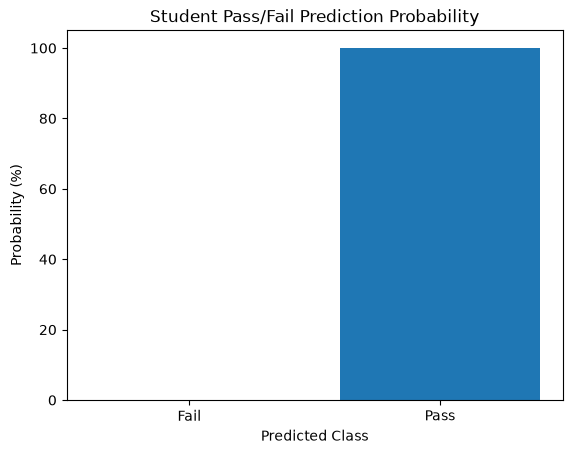

In [17]:
prob_values = probabilities[0] * 100

plt.bar(["Fail", "Pass"], prob_values)

plt.title("Student Pass/Fail Prediction Probability")
plt.xlabel("Predicted Class")
plt.ylabel("Probability (%)")
plt.ylim(0, 105)

plt.show()

In [18]:
df.to_csv("student_pass_fail_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [19]:
import os

print(os.path.exists("student_pass_fail_dataset.csv"))

True


In [20]:
results = pd.DataFrame({
    "Actual_Result": y_test.values,
    "Predicted_Result": y_pred
})

results.to_csv("student_prediction_results.csv", index=False)

print("Prediction results saved successfully!")

Prediction results saved successfully!


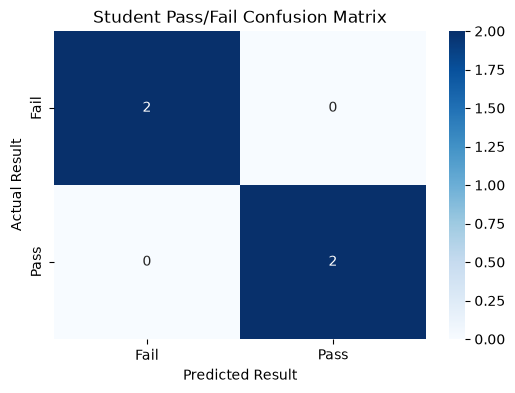

Confusion matrix saved successfully!


In [21]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fail', 'Pass'],
    yticklabels=['Fail', 'Pass']
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Student Pass/Fail Confusion Matrix")

plt.savefig("confusion_matrix.png", dpi=300, bbox_inches='tight')

plt.show()

print("Confusion matrix saved successfully!")

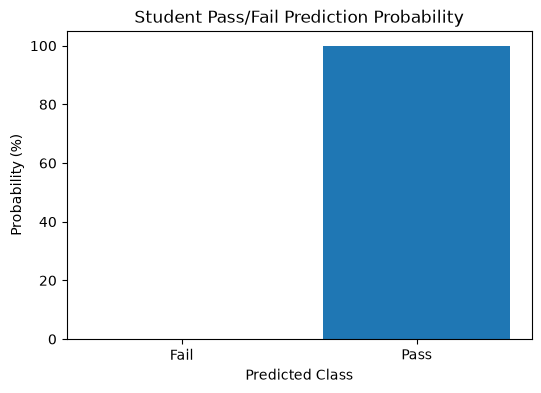

Probability graph saved successfully!


In [22]:
plt.figure(figsize=(6, 4))

prob_values = probabilities[0] * 100

plt.bar(["Fail", "Pass"], prob_values)

plt.title("Student Pass/Fail Prediction Probability")
plt.xlabel("Predicted Class")
plt.ylabel("Probability (%)")
plt.ylim(0, 105)

plt.savefig("prediction_probability.png", dpi=300, bbox_inches='tight')

plt.show()

print("Probability graph saved successfully!")

In [23]:
import joblib

joblib.dump(model, "student_pass_fail_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [24]:
import os

for file in os.listdir():
    if file.endswith((".csv", ".png", ".pkl", ".ipynb")):
        print(file)

 NumPy Random Numbers, Reproducibility & Performance Tips.ipynb
blank_plot.png
bmw_cars_market_dataset_synthetic.csv
cinema.py.ipynb
cinema_booking.py.ipynb
client_retail_sales.csv
clothing_store_customers.csv
confusion_matrix.png
creating arrays in numpy.ipynb
customers_with_groups.csv
customers_with_groups_final.csv
customer_data.csv
customer_groups.png
customer_groups_readable.png
ecommerce_sales_analytics_5000.csv
healthcare_patient_analytics_seaborn.csv
House_Price_Prediction.ipynb
kmeans_model.pkl
loans_with_clusters.csv
loan_data.csv
main..ipynb
mushrooms.csv
my_customers_with_groups.csv
my_group_profiles.csv
Nested loop.ipynb
panda series.ipynb
Pandas Indexing & Selection - loc & iloc.ipynb
pca_customer_project.ipynb
prediction_probability.png
retail_sales.csv
scaler.pkl
Student_Pass_Fail_Classification.ipynb
student_pass_fail_dataset.csv
student_pass_fail_model.pkl
student_prediction_results.csv
telecom_customer_churn_feature_engineering.csv
titanic.csv
Untitled.ipynb
Untitled